# Estimating Breast Tumor Size with Linear Regression

## Introduction

This is my second machine learning project, developed to practice **linear regression** and understand the steps involved in building and evaluating a predictive model.

The goal is to explore whether measurements of cell nuclei from breast biopsy images can help estimate **tumor size in centimeters**. 

## Dataset

This project uses the [Breast Cancer Wisconsin (Prognostic) dataset](https://archive.ics.uci.edu/dataset/16/breast+cancer+wisconsin+prognostic) from the UCI Machine Learning Repository. It contains 198 breast cancer cases, including cell-nucleus measurements and the diameter of the surgically removed tumor.

For this project:

- **Target:** `tumor_size`, measured in centimeters.
- **Input features:** selected cell-nucleus measurements from biopsy images as well as lymph nodes.
- **Excluded variables:** patient ID, recurrence outcome, and follow-up time.

## Project Objectives

1. Explore the dataset and understand its variables.
2. Study the correlation between variables.
3. Prepare the data and prevent data leakage.
4. Build a simple baseline and a linear regression model.
5. Evaluate model performance using MAE, RMSE, and R².
6. Interpret the results and discuss the model’s limitations.

## Dataset Attribution

Wolberg, W., Street, W., & Mangasarian, O. (1995). *Breast Cancer Wisconsin (Prognostic)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5GK50. Licensed under CC BY 4.0.

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the Breast Cancer Wisconsin (Prognostic) dataset
dataset = fetch_ucirepo(id=16)

# Copy all columns into a pandas DataFrame
df = dataset.data.original.copy()

display(df.head())

,ID,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,...,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status,Outcome
0,119513,31,18.02,27.60,117.50,1013.0,0.09489,0.1036,0.1086,0.07055,...,1436.0,0.1195,0.1926,0.3140,0.1170,0.2677,0.08113,5.0,5.0,N
1,8423,61,17.99,10.38,122.80,1001.0,0.11840,0.2776,0.3001,0.14710,...,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,3.0,2.0,N
2,842517,116,21.37,17.44,137.50,1373.0,0.08836,0.1189,0.1255,0.08180,...,1949.0,0.1188,0.3449,0.3414,0.2032,0.4334,0.09067,2.5,0.0,N
3,843483,123,11.42,20.38,77.58,386.1,0.14250,0.2839,0.2414,0.10520,...,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,2.0,0.0,N
4,843584,27,20.29,14.34,135.10,1297.0,0.10030,0.1328,0.1980,0.10430,...,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,3.5,0.0,R


In [2]:
df.shape

(198, 35)

In [3]:
# Display the column names
print("Columns:", df.columns.tolist())

Columns: ['ID', 'Time', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'tumor_size', 'lymph_node_status', 'Outcome']


In [4]:
# 1. Check duplicate records (all column values match)
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [5]:
# Count duplicate column names
print("Duplicate column names:", df.columns.duplicated().sum())

Duplicate column names: 0


In [6]:
# Check columns with identical contents
identical_columns = []

for i in range(df.shape[1]):
    for j in range(i + 1, df.shape[1]):
        if df.iloc[:, i].equals(df.iloc[:, j]):
            identical_columns.append((df.columns[i], df.columns[j]))
            
print("Number of identical column pairs:", len(identical_columns))

Number of identical column pairs: 0


In [7]:
missing = df.isna().sum()
print(missing[missing > 0])

lymph_node_status    4
dtype: int64


In [8]:
# Remove rows containing missing values
df = df.dropna()

In [9]:
# Check the result
print("Remaining patients:", len(df))
print("Remaining missing values:", df.isna().sum().sum())

Remaining patients: 194
Remaining missing values: 0


In [10]:
# Remove columns we will not use
df = df.drop(columns=["ID", "Time", "Outcome"])

# Check the remaining columns
print(df.columns.tolist())

['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'tumor_size', 'lymph_node_status']


In [11]:
# Show the data type of each column
print(df.dtypes)

radius1               float64
texture1              float64
perimeter1            float64
area1                 float64
smoothness1           float64
compactness1          float64
concavity1            float64
concave_points1       float64
symmetry1             float64
fractal_dimension1    float64
radius2               float64
texture2              float64
perimeter2            float64
area2                 float64
smoothness2           float64
compactness2          float64
concavity2            float64
concave_points2       float64
symmetry2             float64
fractal_dimension2    float64
radius3               float64
texture3              float64
perimeter3            float64
area3                 float64
smoothness3           float64
compactness3          float64
concavity3            float64
concave_points3       float64
symmetry3             float64
fractal_dimension3    float64
tumor_size            float64
lymph_node_status     float64
dtype: object


In [12]:
# Summarize every numerical column
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
radius1,194.0,17.402320,3.171672,10.950000,15.052500,17.290000,19.580000,27.22000
texture1,194.0,22.300979,4.335292,10.380000,19.342500,21.795000,24.782500,39.28000
perimeter1,194.0,114.781495,21.430694,71.900000,98.160000,113.700000,129.650000,182.10000
area1,194.0,969.092268,353.159959,361.600000,702.525000,929.100000,1193.500000,2250.00000
smoothness1,194.0,0.102774,0.012607,0.074970,0.093900,0.102200,0.111375,0.14470
compactness1,194.0,0.142642,0.050229,0.046050,0.109850,0.131750,0.172200,0.31140
concavity1,194.0,0.156309,0.070942,0.023980,0.106075,0.152050,0.200500,0.42680
concave_points1,194.0,0.086808,0.033962,0.020310,0.063760,0.086075,0.103925,0.20120
symmetry1,194.0,0.192885,0.027679,0.130800,0.174075,0.189350,0.209550,0.30400
fractal_dimension1,194.0,0.062743,0.007289,0.050250,0.056718,0.061715,0.066810,0.09744


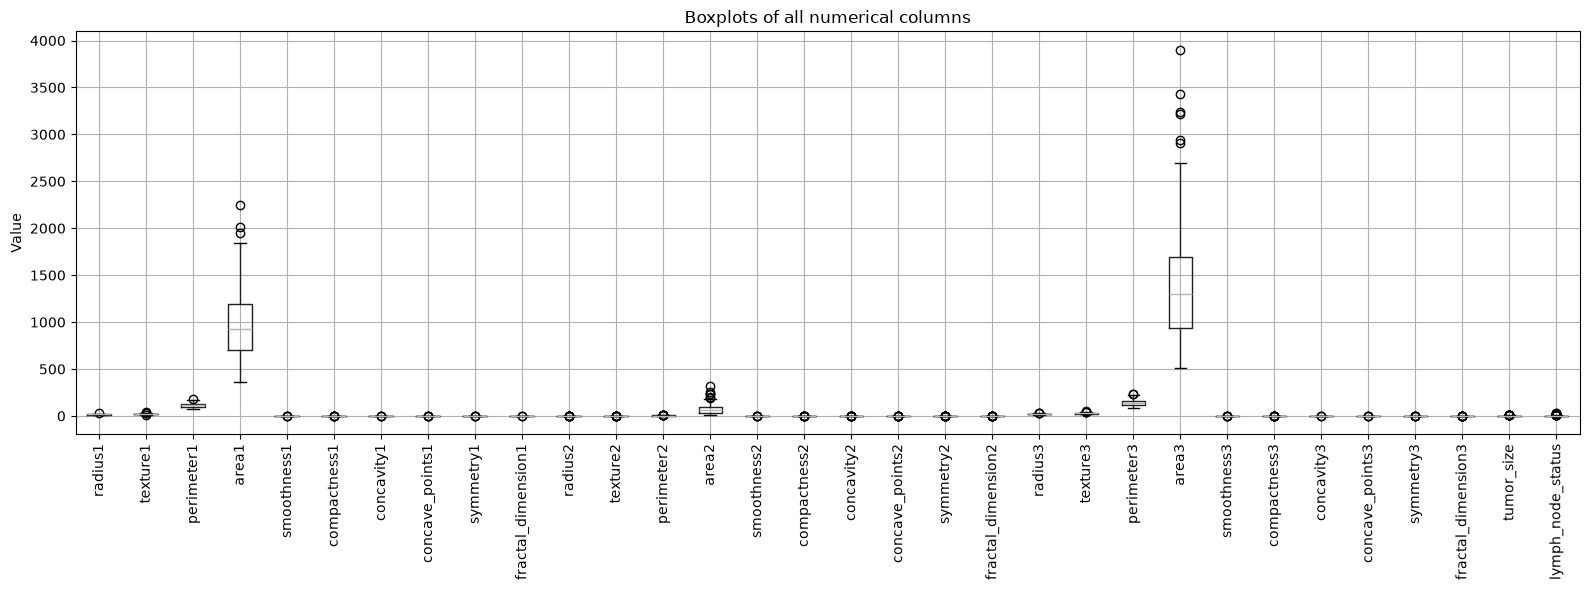

In [13]:
# Check for possible outliers
import matplotlib.pyplot as plt

df.boxplot(figsize=(16, 6), rot=90)
plt.title("Boxplots of all numerical columns")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

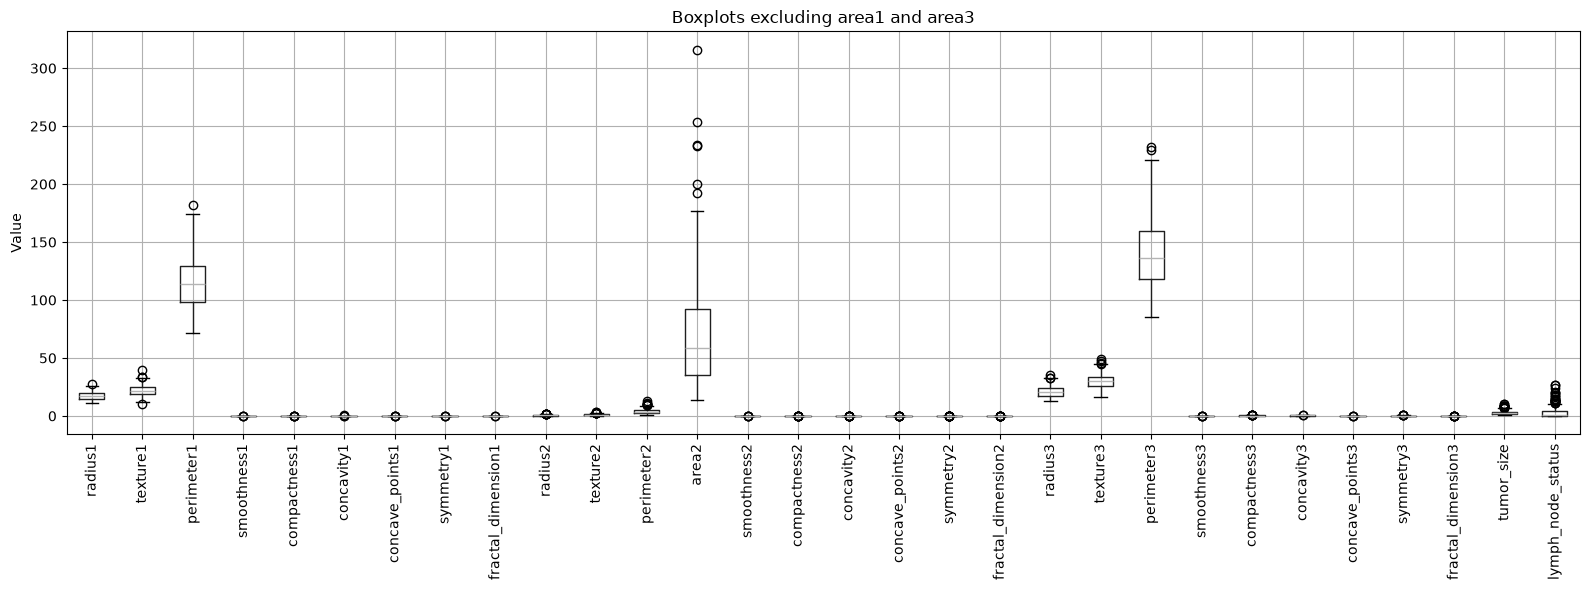

In [14]:
# Check for possible outliers (all variables except area1 and area3 which have larger values as the other variables in the dataset ) 
import matplotlib.pyplot as plt

df.drop(columns=["area1", "area3"]).boxplot(
    figsize=(16, 6), rot=90
)

plt.title("Boxplots excluding area1 and area3")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

**Boxplots were used to inspect potential outliers. No observations were removed because unusual values alone do not indicate data errors.**

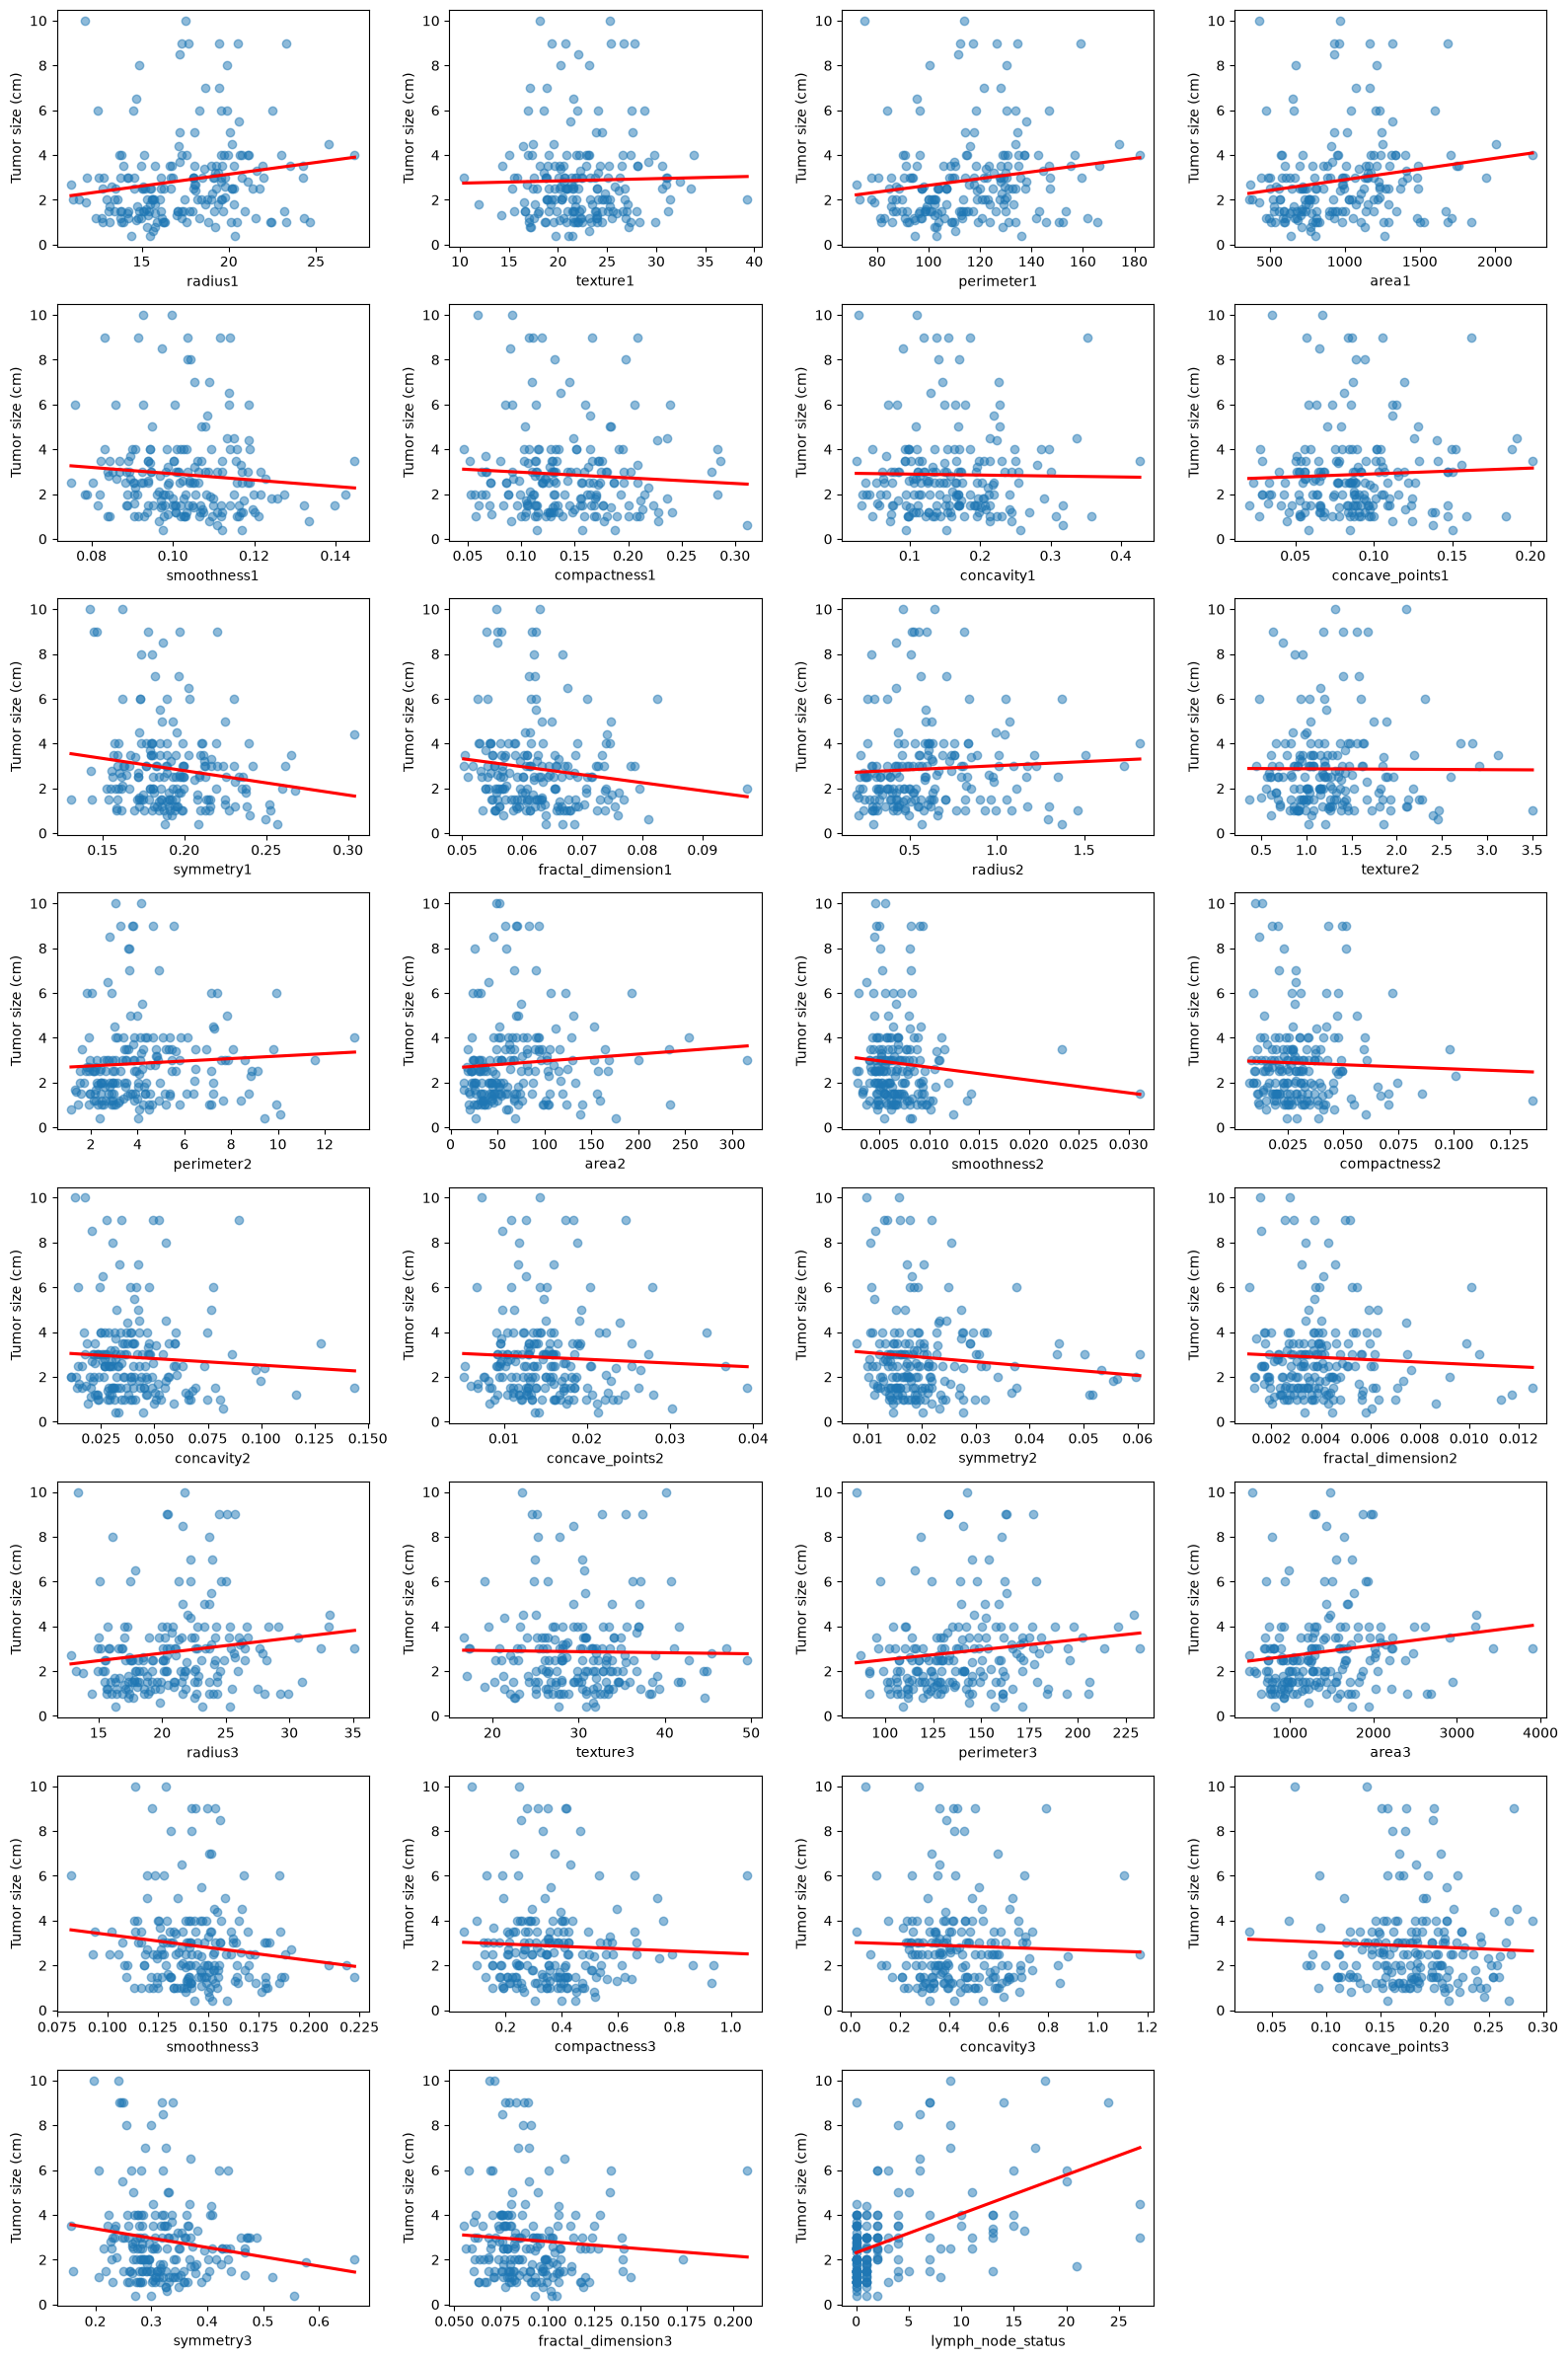

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = df.columns.drop("tumor_size")

fig, axes = plt.subplots(8, 4, figsize=(16, 24))
axes = axes.flatten()

for ax, column in zip(axes, columns):
    sns.regplot(data=df, x=column, y="tumor_size", ax=ax, ci=None, scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    ax.set_ylabel("Tumor size (cm)")

for ax in axes[len(columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

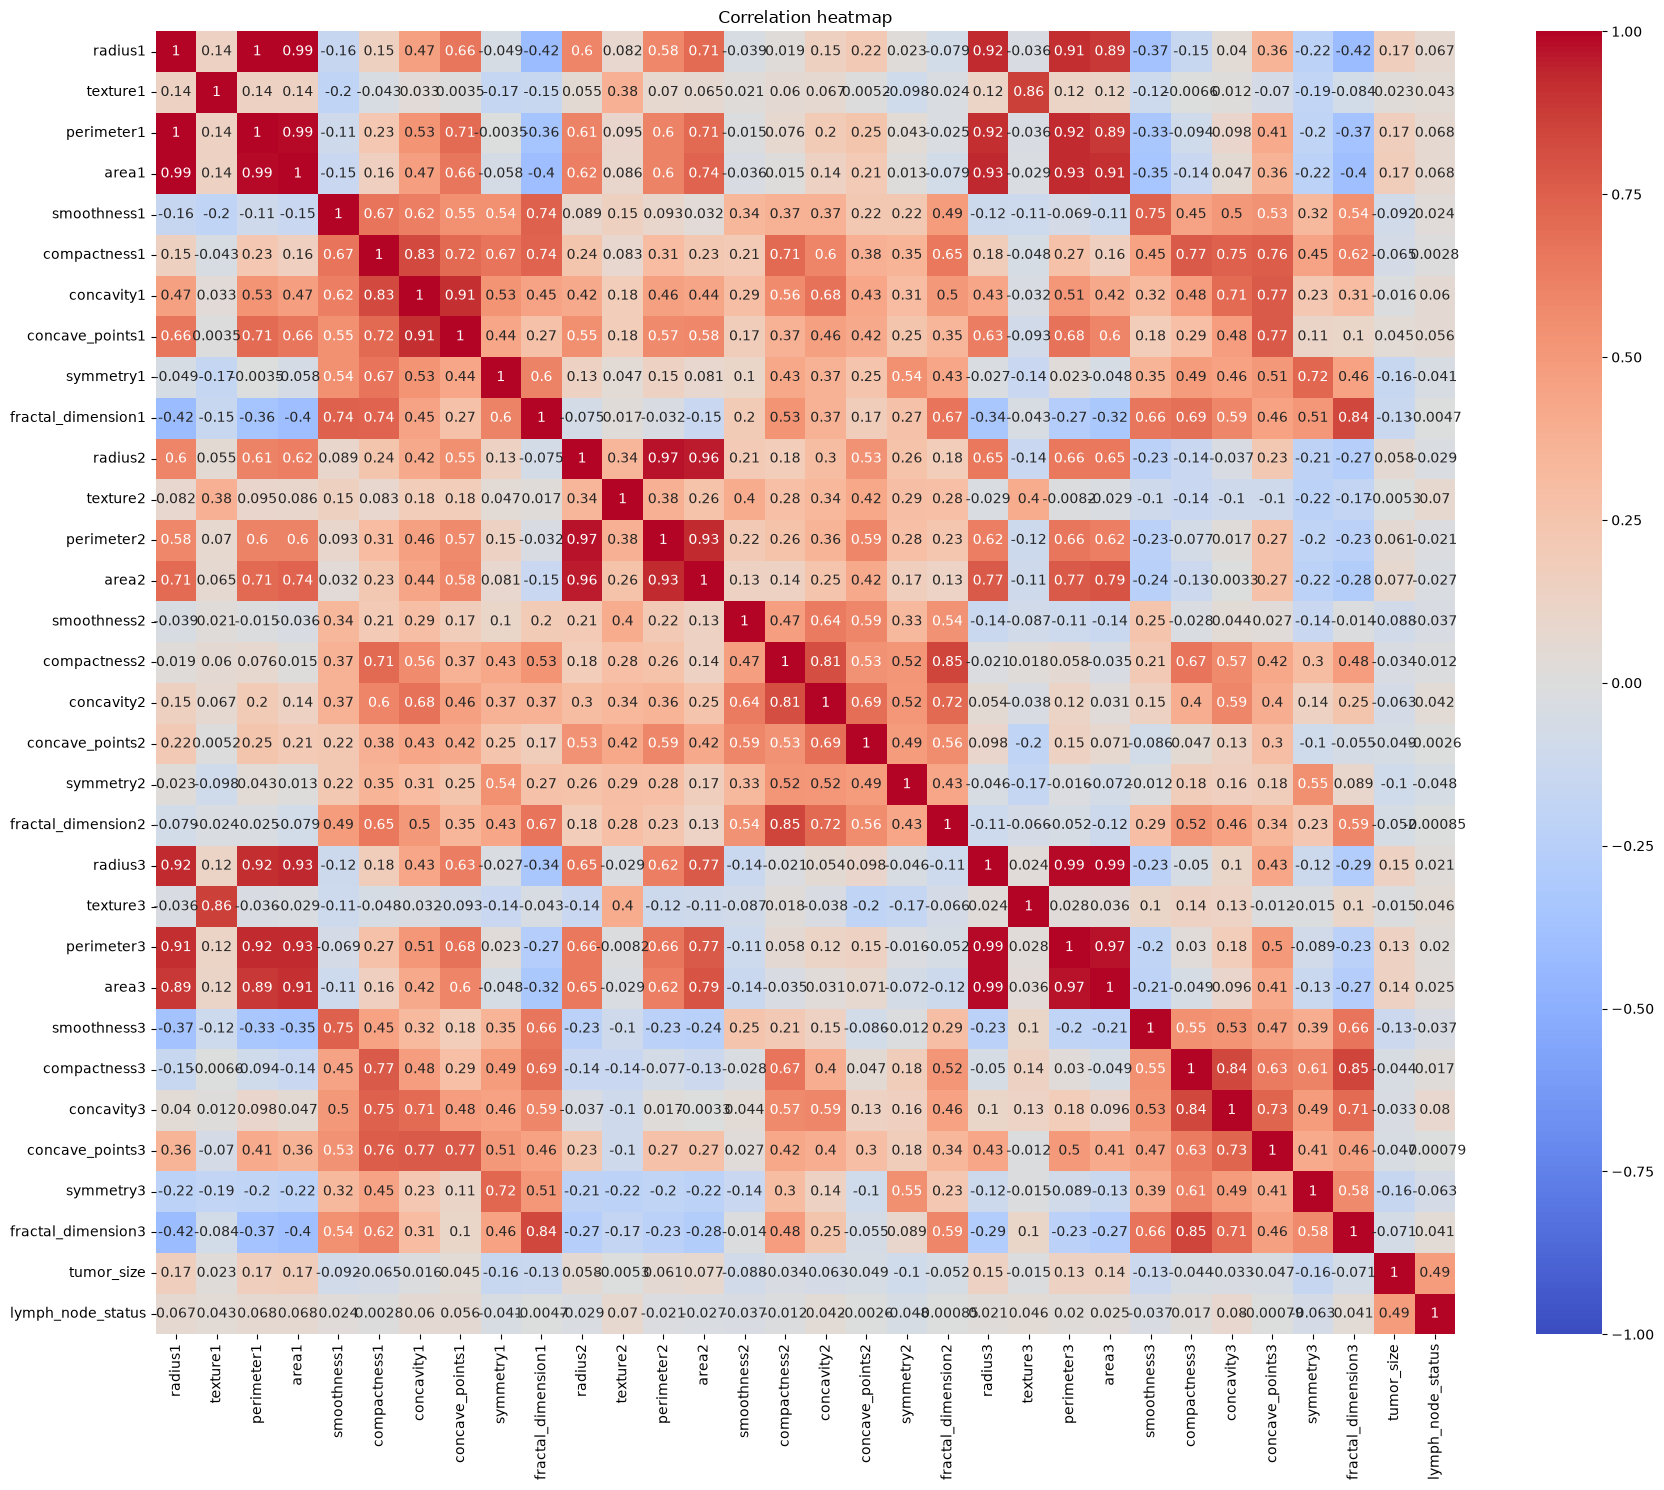

In [16]:
# Calculate Pearson correlations between numerical variables
correlation = df.corr()

plt.figure(figsize=(18, 15))

sns.heatmap(correlation, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True)

plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()




As we can see, many variables have a moderate to strong correlation and sometimes a negative correlation, let's look at the correlation between tumor size and the other variables.

In [17]:
print(correlation["tumor_size"].drop("tumor_size").sort_values(ascending=False))

lymph_node_status     0.487617
area1                 0.173039
radius1               0.171169
perimeter1            0.165332
radius3               0.146101
area3                 0.140995
perimeter3            0.133517
area2                 0.077081
perimeter2            0.061302
radius2               0.057531
concave_points1       0.044671
texture1              0.022644
texture2             -0.005347
texture3             -0.014807
concavity1           -0.015586
concavity3           -0.032835
compactness2         -0.034256
compactness3         -0.043581
concave_points3      -0.046552
concave_points2      -0.048663
fractal_dimension2   -0.052239
concavity2           -0.062796
compactness1         -0.064624
fractal_dimension3   -0.070588
smoothness2          -0.087624
smoothness1          -0.091558
symmetry2            -0.100997
smoothness3          -0.131006
fractal_dimension1   -0.133686
symmetry1            -0.155044
symmetry3            -0.158267
Name: tumor_size, dtype: float64


- lymph_node_status has the strongest positive correlation with tumor size (r = 0.49), indicating a moderate relationship. All other measurements show weak correlations (r < 0.18).
- These findings suggest limited predictive information from individual nucleus measurements, but model evaluation is needed to assess their combined performance.

In [18]:
from sklearn.model_selection import train_test_split

# Inputs: all remaining columns except tumor size
X = df.drop(columns=["tumor_size"])

# Target: tumor size
y = df["tumor_size"]

# Split: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training patients:", len(X_train))
print("Test patients:", len(X_test))

Training patients: 155
Test patients: 39


In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# 1. Create and train the baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# 2. Create and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Predict tumor sizes for the test patients
baseline_predictions = baseline.predict(X_test)
model_predictions = model.predict(X_test)

# 4. Compare actual sizes with both models' predictions
comparison = pd.DataFrame({"Actual size (cm)": y_test,"Baseline prediction (cm)": baseline_predictions,
                           "Linear regression prediction (cm)": model_predictions})

display(comparison)

,Actual size (cm),Baseline prediction (cm),Linear regression prediction (cm)
141,3.0,2.935484,2.888561
17,4.0,2.935484,3.199570
158,3.0,2.935484,2.081746
99,1.5,2.935484,2.874081
70,1.0,2.935484,4.010021
156,2.5,2.935484,2.889492
57,7.0,2.935484,5.142510
16,1.3,2.935484,0.825021
115,1.5,2.935484,3.143354
114,2.5,2.935484,5.788556


The baseline always predicts 2.935484 cm because this is the mean tumor size in the training data.
Linear regression gives different predictions based on each patient’s measurements. Sometimes it performs better than the baseline, and sometimes worse.

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate the baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = mean_squared_error(y_test, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_test, baseline_predictions)

# Evaluate linear regression
model_mae = mean_absolute_error(y_test, model_predictions)
model_rmse = mean_squared_error(y_test, model_predictions) ** 0.5
model_r2 = r2_score(y_test, model_predictions)

# Create the comparison table
results = pd.DataFrame({"Model": ["Baseline", "Linear regression"], "MAE (cm)": [baseline_mae, model_mae], 
                        "RMSE (cm)": [baseline_rmse, model_rmse], "R²": [baseline_r2, model_r2]})

display(results)

,Model,MAE (cm),RMSE (cm),R²
0,Baseline,1.132754,1.419340,-0.060138
1,Linear regression,1.359837,1.726786,-0.569158


The baseline model outperforms linear regression, with lower MAE (1.13 and 1.36 cm) and RMSE (1.42 and 1.73 cm). Both models have negative R² scores, indicating worse performance than predicting the test-set mean tumor size. On this test set, linear regression provides no improvement over the simple baseline.

In [21]:
# Correlations with tumor size, using training data only
train_correlations = X_train.corrwith(y_train)

# Select the four strongest correlations, positive or negative
top_four = train_correlations.abs().nlargest(4).index.tolist()

print("Selected variables:", top_four)
print(train_correlations[top_four])

# Train a new model using those four variables
model_four = LinearRegression()
model_four.fit(X_train[top_four], y_train)

Selected variables: ['lymph_node_status', 'symmetry1', 'area1', 'radius1']
lymph_node_status    0.497803
symmetry1           -0.212590
area1                0.192700
radius1              0.186365
dtype: float64


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.18,-13.5 , 0. , -0.37]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['lymph_node_status','symmetry1','area1','radius1']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.312
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [22]:
# Predict using the four-variable model
four_predictions = model_four.predict(X_test[top_four])

# Calculate its test metrics
four_results = pd.DataFrame({
    "Model": ["Linear regression 4 variables"],
    "MAE (cm)": [mean_absolute_error(y_test, four_predictions)],
    "RMSE (cm)": [
        mean_squared_error(y_test, four_predictions) ** 0.5],
    "R²": [r2_score(y_test, four_predictions)]})

display(four_results)

,Model,MAE (cm),RMSE (cm),R²
0,Linear regression 4 variables,1.18186,1.483492,-0.158137


The four-variable model performs better than the original linear regression, but is still worse than the baseline.

In [23]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import make_pipeline

# Use the same five splits for each approach
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {"Baseline": DummyRegressor(strategy="mean"),"All variables": LinearRegression(),
          "Four selected variables": make_pipeline(SelectKBest(f_regression, k=4), LinearRegression())}

rows = []

for name, estimator in models.items():
    scores = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")

    errors = -scores

    rows.append({"Model": name, "Average MAE (cm)": errors.mean(), "MAE standard deviation (cm)": errors.std()})

cv_results = pd.DataFrame(rows)
display(cv_results.round(3))

,Model,Average MAE (cm),MAE standard deviation (cm)
0,Baseline,1.476,0.374
1,All variables,1.693,0.271
2,Four selected variables,1.367,0.214


In [24]:
# Train using only lymph-node status
model_one = LinearRegression()
model_one.fit(X_train[["lymph_node_status"]], y_train)

# Predict tumor size
one_predictions = model_one.predict(X_test[["lymph_node_status"]])

# Display scores
print("MAE:", round(mean_absolute_error(y_test, one_predictions), 3))
print("RMSE:", round(mean_squared_error(y_test, one_predictions) ** 0.5, 3))
print("R²:", round(r2_score(y_test, one_predictions), 3))

MAE: 1.019
RMSE: 1.311
R²: 0.096


In [25]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(LinearRegression(), X_train[["lymph_node_status"]], y_train, cv=cv, scoring="neg_mean_absolute_error")
errors = -scores
print("Average MAE (cm):", (errors.mean()))
print("MAE standard deviation (cm):", (errors.std()))

Average MAE (cm): 1.3160061628907873
MAE standard deviation (cm): 0.2786077837217208


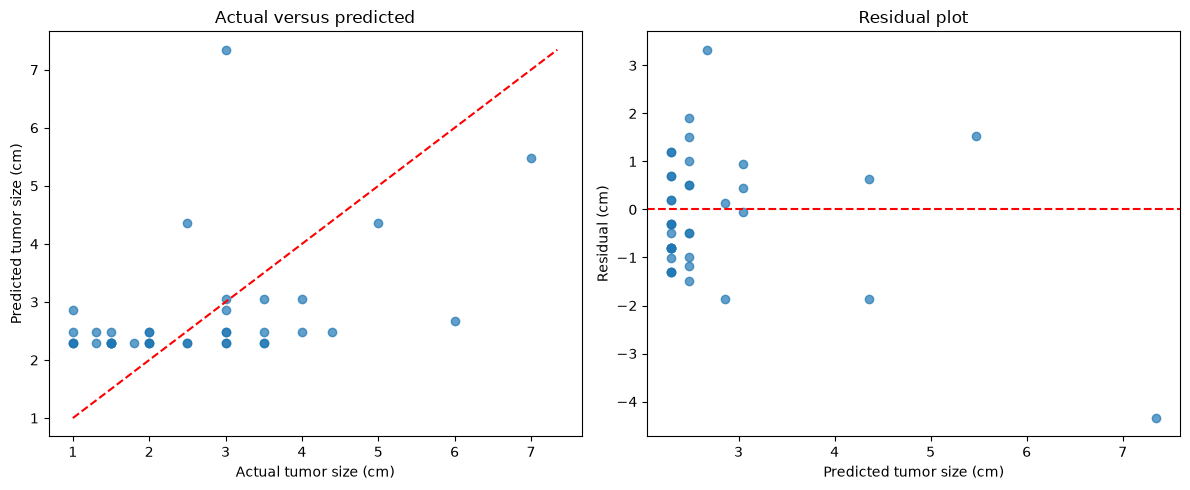

In [26]:
# Residual = actual size minus predicted size
residuals = y_test - one_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Actual versus predicted sizes
axes[0].scatter(y_test, one_predictions, alpha=0.7)

lower = min(y_test.min(), one_predictions.min())
upper = max(y_test.max(), one_predictions.max())

axes[0].plot([lower, upper], [lower, upper], "r--")
axes[0].set_xlabel("Actual tumor size (cm)")
axes[0].set_ylabel("Predicted tumor size (cm)")
axes[0].set_title("Actual versus predicted")

# 2. Residuals versus predicted sizes
axes[1].scatter(one_predictions, residuals, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted tumor size (cm)")
axes[1].set_ylabel("Residual (cm)")
axes[1].set_title("Residual plot")

plt.tight_layout()
plt.show()

### Conclusion
Linear regression showed limited predictive accuracy on this test set. Selecting four input variables improved performance compared with the full model, but it still did not outperform the baseline. Using lymph-node status alone also produced substantial prediction errors, often overestimating small tumors and underestimating large tumors. These results suggest that the evaluated linear models were insufficient for accurately predicting tumor size.